# ESCM 2.0 — Inhibition diagnostic and one controlled correction

## Decision point

Notebook 19 demonstrated persistence for all five tested geometries, but complete replacement only for **vertical and horizontal** structures. Diagonal, L-shaped, and stepped shapes left old pixels firing. We will **not** add another mechanism or perform an open-ended parameter search.

This notebook asks one question: **do obsolete pixels survive because the new structure delivers less inhibition to those pixels?** It measures the exact inhibitory connection geometry and reconstructs time-dependent inhibitory drive from actual presynaptic spike trains.

We then test exactly **one predeclared modification**, extending the inhibition annulus's outer radius from 4.5 to 5.5 pixels. No weight, neuronal equation, input strength, or inner radius changes. This is a hypothesis test, **not** an optimized architecture; if it fails or damages controls, retain the original model and record the limitation.

**Inputs and acceptance criteria** are inherited from Notebook 19: 9×9 grid, five shapes, events at 2/4/6 and 40/42/44 ms, fixed evaluation windows [90,105) and [105,120) ms, ≥2 spikes per desired pixel per window, zero old/background spikes. Identical solo controls must pass. This is a bounded synthetic test, not generalization to all event-camera inputs.

## 1. Reproduce Notebook 19 without modifying the network

We reuse its shape definitions and LIF formulation exactly. The only new argument, `outer_radius`, defaults to **4.5**, the previously selected value. `Iexc` is assigned to 8 by an autapse on each output spike; inhibitory spikes add a distance-weighted current. No custom persistence gate or scheduling rules.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"
width = height = 9
n = width * height
xy = np.column_stack(np.unravel_index(np.arange(n), (height, width)))[..., ::-1]
tm, tx, te, ti = 10., 3., 5., 12.  # ms
self_weight, threshold = 8., 1.
sigma_e, sigma_i = 0.9, 2.5
radius_e, radius_i = 1.5, 4.5

def pixels(coordinates):
    return np.array([y*width+x for x, y in coordinates], dtype=int)

shapes = {
    "vertical": (
        pixels([(2, y) for y in range(2, 7)]),
        pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (
        pixels([(x, 2) for x in range(2, 7)]),
        pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (
        pixels([(x, x) for x in range(1, 6)]),
        pixels([(x+3, x) for x in range(1, 6)])),
    "L shape": (
        pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
        pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (
        pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
        pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
}
for name, (old, new) in shapes.items():
    assert len(old) == len(new) == 5
    assert len(set(old) | set(new)) == 10
    assert all(0 <= p < n for p in np.r_[old, new]), name

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def simulate(schedule, beta=22., g_i=0.1, g_e=0., surround=True, dt=0.05, outer_radius=4.5):
    b2.start_scope()
    b2.defaultclock.dt = dt * b2.ms

    # Each schedule entry is (pixel_ids, pulse_times_ms, row_delay_ms).
    # The recurrent graph below never depends on these pixel identities.
    ids, times = [], []
    for pixels, pulses, row_delay in schedule:
        for pulse in pulses:
            for j, pixel in enumerate(pixels):
                ids.append(int(pixel))
                times.append(pulse + j * row_delay)
    order = np.argsort(times, kind="stable")
    camera = b2.SpikeGeneratorGroup(
        n, np.asarray(ids, dtype=int)[order],
        np.asarray(times, dtype=float)[order] * b2.ms)

    parameters = dict(tau_m=tm*b2.ms, tau_ext=tx*b2.ms,
                      tau_exc=te*b2.ms, tau_inh=ti*b2.ms,
                      v_threshold=threshold, self_gain=self_weight,
                      camera_gain=beta)
    neurons = b2.NeuronGroup(n, """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """, threshold="v > v_threshold", reset="v = 0",
        method="exact", namespace=parameters)
    neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = 0

    feed = b2.Synapses(camera, neurons, on_pre="Iext_post += camera_gain",
                       namespace=parameters)
    feed.connect(j="i")
    autapse = b2.Synapses(neurons, neurons,
                          on_pre="Iexc_post = self_gain", namespace=parameters)
    autapse.connect(i=np.arange(n), j=np.arange(n))
    objects = [camera, neurons, feed, autapse]

    distances = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
    # distances[post, pre], so the row is the postsynaptic cell.
    if g_i > 0:
        min_radius = 1.5 if surround else 0.
        post, pre = np.where((distances > min_radius) &
                             (distances <= outer_radius))
        weights = g_i * np.exp(-distances[post, pre]**2/(2*sigma_i**2))
        lateral_inh = b2.Synapses(neurons, neurons, "w : 1",
                                 on_pre="Iinh_post += w")
        lateral_inh.connect(i=pre, j=post)
        lateral_inh.w = weights
        objects.append(lateral_inh)
    if g_e > 0:
        post, pre = np.where((distances > 0) & (distances <= radius_e))
        weights = g_e * np.exp(-distances[post, pre]**2/(2*sigma_e**2))
        lateral_exc = b2.Synapses(neurons, neurons, "w : 1",
                                 on_pre="Iexc_post += w")
        lateral_exc.connect(i=pre, j=post)
        lateral_exc.w = weights
        objects.append(lateral_exc)

    spike_monitor = b2.SpikeMonitor(neurons)
    objects.append(spike_monitor)
    b2.Network(*objects).run(130*b2.ms)
    return dict(t=np.asarray(spike_monitor.t/b2.ms),
                i=np.asarray(spike_monitor.i, dtype=int))


In [3]:
def evaluate(old, new, second_start=40., row_delay=0., dt=0.05, outer_radius=4.5):
    pulse_old = (2., 4., 6.)
    pulse_new = (second_start, second_start+2, second_start+4)
    old_input = (old, pulse_old, row_delay)
    new_input = (new, pulse_new, row_delay)
    old_run = simulate([old_input], dt=dt, outer_radius=outer_radius)
    new_run = simulate([new_input], dt=dt, outer_radius=outer_radius)
    replacement = simulate([old_input, new_input], dt=dt, outer_radius=outer_radius)
    windows = ((90., 105.), (105., 120.))
    def per_pixel(run, indices):
        return np.array([[np.count_nonzero((run["i"] == pixel) &
                   (run["t"] >= left) & (run["t"] < right))
                   for pixel in indices] for left, right in windows])
    old_ctrl = per_pixel(old_run, old)
    new_ctrl = per_pixel(new_run, new)
    old_after = per_pixel(replacement, old)
    new_after = per_pixel(replacement, new)
    background = np.setdiff1d(np.arange(n), np.r_[old, new])
    other = per_pixel(replacement, background)
    stable_old = (old_ctrl >= 2).all(axis=0)
    stable_new = (new_ctrl >= 2).all(axis=0)
    removed_old = (old_after == 0).all(axis=0)
    stable_new_after = (new_after >= 2).all(axis=0)
    quiet = (other == 0).all(axis=0)
    return dict(old_control=int(stable_old.sum()), new_control=int(stable_new.sum()),
                old_silent=int(removed_old.sum()), new_persistent=int(stable_new_after.sum()),
                off_target=int((~quiet).sum()),
                success=bool(stable_old.all() and stable_new.all() and
                             removed_old.all() and stable_new_after.all() and quiet.all()))

## 2. Exact structural input from the new shape

The excitatory and inhibitory graph is homogeneous and determined by Euclidean distance. For target old pixel \(i\), its total **potential** inhibition from the five new pixels is

\[
C_{B\to i}=\sum_{j\in B}w_{ij},\quad
w_{ij}=g_I\exp\!\left(-\frac{\|x_i-x_j\|^2}{2\sigma_I^2}\right)
\mathbf 1\{1.5<\|x_i-x_j\|\le R_I\}.
\]

This is the jump in inhibitory current **if all five new pixels fired once each**. It is not the actual drive because firing rates and timings differ. We calculate both baseline and the single proposed radius change. A structurally weak surviving pixel supports—but does not prove—the connectivity hypothesis.

outer_radius               4.5       5.5
geometry   old_pixel                    
L shape    20         0.149143  0.158971
           29         0.164207  0.176700
           38         0.156757  0.170291
           39         0.268855  0.268855
           40         0.188322  0.188322
diagonal   10         0.074341  0.084169
           20         0.141373  0.151201
           30         0.208405  0.218233
           40         0.257081  0.257081
           50         0.257081  0.257081
horizontal 20         0.152646  0.166180
           21         0.197579  0.197579
           22         0.209232  0.209232
           23         0.197579  0.197579
           24         0.152646  0.166180
stepped    20         0.102145  0.124465
           21         0.212079  0.212079
           30         0.214110  0.214110
           31         0.233255  0.233255
           40         0.280401  0.280401
vertical   20         0.152646  0.166180
           29         0.197579  0.197579
           38         0.209232  0.209232
           47         0.197579  0.197579
           56         0.152646  0.166180

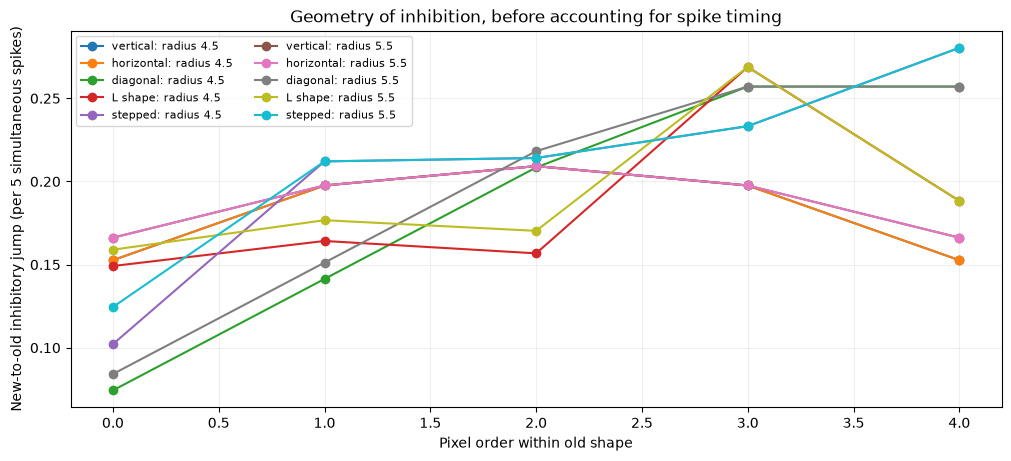

In [4]:
distances = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)

def inhibitory_matrix(outer_radius):
    active = (distances > 1.5) & (distances <= outer_radius)
    return 0.1 * np.exp(-distances**2 / (2 * sigma_i**2)) * active

rows = []
for radius in (4.5, 5.5):
    weights_matrix = inhibitory_matrix(radius)
    for shape, (old, new) in shapes.items():
        potential = weights_matrix[np.ix_(old, new)].sum(axis=1)
        for j, (pixel, value) in enumerate(zip(old, potential)):
            rows.append(dict(outer_radius=radius, geometry=shape,
                             old_pixel=int(pixel), old_x=int(xy[pixel, 0]),
                             old_y=int(xy[pixel, 1]), potential_new_to_old=value))
structural = pd.DataFrame(rows)
display(structural.pivot_table(index=["geometry", "old_pixel"],
    columns="outer_radius", values="potential_new_to_old"))
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for (geometry, radius), group in structural.groupby(["geometry", "outer_radius"], sort=False):
    ax.plot(np.arange(5), group.potential_new_to_old,
            marker="o", label=f"{geometry}: radius {radius:g}")
ax.set(xlabel="Pixel order within old shape", ylabel="New-to-old inhibitory jump (per 5 simultaneous spikes)",
       title="Geometry of inhibition, before accounting for spike timing")
ax.grid(alpha=0.2)
ax.legend(fontsize=8, ncol=2)
plt.show()

## 3. Actual inhibitory drive, decomposed by source

Each spike from new pixel \(j\) adds \(w_{ij}\) to the inhibitory current in old pixel \(i\), which then decays exponentially with \(\tau_I=12\) ms. The contribution from the new structure is therefore

\[
I_{B\to i}(t)=\sum_{j\in B}\sum_{s\in S_j,\,s<t}w_{ij}\exp[-(t-s)/\tau_I],
\]

where \(S_j\) is the actual spike train produced by new neuron \(j\). We reconstruct contributions separately for old and new presynaptic sets. This is not an independent numerical solution of the membrane model; it **is** an exact reconstruction of exponential synaptic currents from recorded spikes, up to Brian2's timestep event convention.

We compare those currents with **per-pixel** old firing after new input. The old-only control demonstrates which old pixels would persist without a replacement stimulus. That distinction prevents confusing fading with suppression.

In [5]:
diagnostics = []
traces = {}
for geometry, (old, new) in tqdm(shapes.items(), desc="Diagnose observed inhibition"):
    control = simulate([(old, (2., 4., 6.), 0.)])
    run = simulate([(old, (2., 4., 6.), 0.), (new, (40., 42., 44.), 0.)])
    traces[geometry] = run
    W = inhibitory_matrix(4.5)
    for idx in old:
        # Number of old spikes in the same late windows as Notebook 19.
        late = sum(np.count_nonzero((run["i"] == idx) & (run["t"] >= a) & (run["t"] < b))
                   for a, b in ((90., 105.), (105., 120.)))
        solo = sum(np.count_nonzero((control["i"] == idx) & (control["t"] >= a) & (control["t"] < b))
                   for a, b in ((90., 105.), (105., 120.)))
        new_spikes = np.isin(run["i"], new) & (run["t"] < 120)
        spikes_t = run["t"][new_spikes]
        spikes_i = run["i"][new_spikes]
        # Reconstruct new-to-old inhibitory current on a 0.5-ms time grid.
        sample_t = np.arange(40., 120., 0.5)
        drive = np.zeros_like(sample_t)
        for source, spike_t in zip(spikes_i, spikes_t):
            mask = sample_t > spike_t
            drive[mask] += W[idx, source] * np.exp(-(sample_t[mask] - spike_t)/ti)
        after = (sample_t >= 50) & (sample_t < 90)
        diagnostics.append(dict(geometry=geometry, old_pixel=int(idx),
            x=int(xy[idx, 0]), y=int(xy[idx, 1]),
            control_spikes_90_120=int(solo), replacement_spikes_90_120=int(late),
            survives=bool(late > 0),
            potential_new_to_old=float(W[idx, new].sum()),
            mean_new_inhibition_50_90=float(drive[after].mean()),
            max_new_inhibition_50_90=float(drive[after].max())))
per_pixel = pd.DataFrame(diagnostics)
display(per_pixel)
print("Old survivors by shape:")
display(per_pixel.groupby("geometry", sort=False).survives.sum().rename("survivors"))

Diagnose observed inhibition: 100%|██████████| 5/5 [00:04<00:00,  1.09it/s]


,geometry,old_pixel,x,y,control_spikes_90_120,replacement_spikes_90_120,survives,potential_new_to_old,mean_new_inhibition_50_90,max_new_inhibition_50_90
0,vertical,20,2,2,16,0,False,0.152646,1.224071,1.910080
1,vertical,29,2,3,16,0,False,0.197579,1.584138,2.476123
2,vertical,38,2,4,15,0,False,0.209232,1.677393,2.620954
3,vertical,47,2,5,16,0,False,0.197579,1.584138,2.476123
4,vertical,56,2,6,16,0,False,0.152646,1.224071,1.910080
5,horizontal,20,2,2,16,0,False,0.152646,1.224071,1.910080
6,horizontal,21,3,2,16,0,False,0.197579,1.584138,2.476123
7,horizontal,22,4,2,15,0,False,0.209232,1.677393,2.620954
8,horizontal,23,5,2,16,0,False,0.197579,1.584138,2.476123
9,horizontal,24,6,2,16,0,False,0.152646,1.224071,1.910080


Old survivors by shape:


geometry
vertical      0
horizontal    0
diagonal      2
L shape       1
stepped       1
Name: survivors, dtype: int64

## 4. Can the structural mechanism explain the failures?

Plot each old neuron's actual mean new-to-old inhibition against its late spike count, distinguishing geometries. If survivors systematically receive less inhibition than suppressed cells, **insufficient inhibition is a plausible explanation**. If not, the failure may involve inhibition timing, older recurrent activity, or coupled dynamics that are not captured by a static weight sum.

This scatterplot is a diagnostic, **not** a causal identification of individual connections.

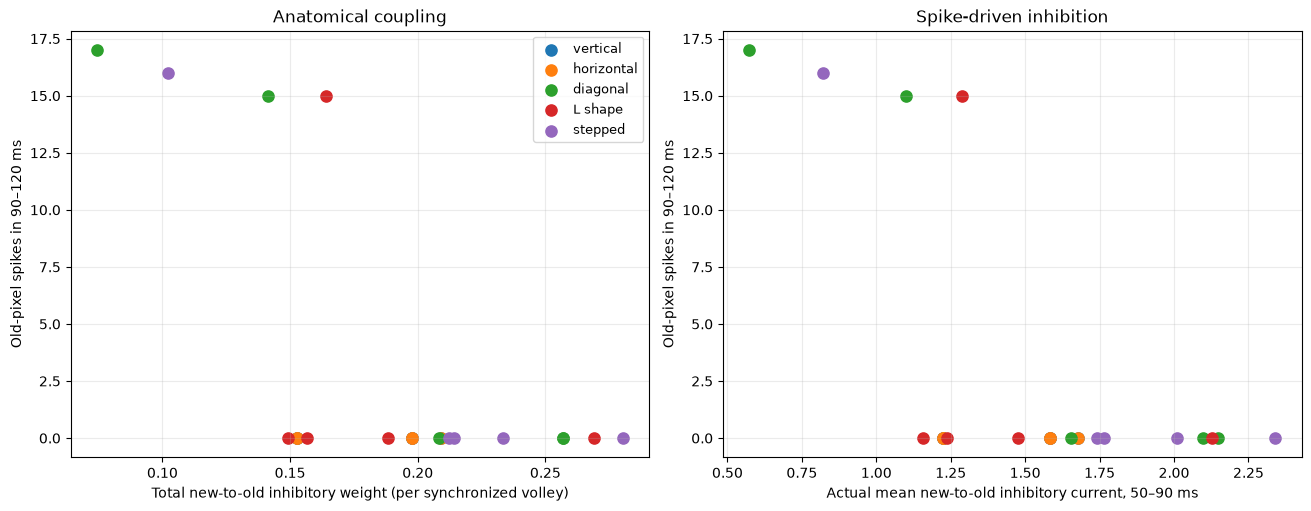

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for geometry, group in per_pixel.groupby("geometry", sort=False):
    axes[0].scatter(group.potential_new_to_old, group.replacement_spikes_90_120,
                    label=geometry, s=65)
    axes[1].scatter(group.mean_new_inhibition_50_90, group.replacement_spikes_90_120,
                    label=geometry, s=65)
axes[0].set(xlabel="Total new-to-old inhibitory weight (per synchronized volley)",
            ylabel="Old-pixel spikes in 90–120 ms", title="Anatomical coupling")
axes[1].set(xlabel="Actual mean new-to-old inhibitory current, 50–90 ms",
            ylabel="Old-pixel spikes in 90–120 ms", title="Spike-driven inhibition")
for ax in axes:
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=9)
plt.show()

## 5. One predeclared correction: extend the inhibitory outer radius

We now test **only** radius 4.5 (baseline) versus 5.5 (single correction). This extends the reach of surround inhibition while keeping the local protected radius at 1.5, and preserves all neuronal and input parameters. It may increase suppression of remote obsolete pixels, but could also impair persistence by increasing within-shape inhibition or impede recruitment of new shapes.

For each geometry, use the same three-run criterion: old alone, new alone, and old followed by new. All five shapes are included in the outcome, including those that failed previously. No cherry-picking of a new winning parameter combination.

Fixed-radius comparison: 100%|██████████| 2/2 [00:07<00:00,  3.64s/it]


,outer_radius,geometry,old_control,new_control,old_silent,new_persistent,off_target,success
0,4.5,vertical,5,5,5,5,0,True
1,4.5,horizontal,5,5,5,5,0,True
2,4.5,diagonal,5,5,3,5,0,False
3,4.5,L shape,5,5,4,5,0,False
4,4.5,stepped,5,5,4,5,0,False
5,5.5,vertical,5,5,5,5,0,True
6,5.5,horizontal,5,5,5,5,0,True
7,5.5,diagonal,5,5,3,5,0,False
8,5.5,L shape,5,5,5,5,0,True
9,5.5,stepped,5,5,4,5,0,False


,sum,count
outer_radius,,
4.5,2,5
5.5,3,5


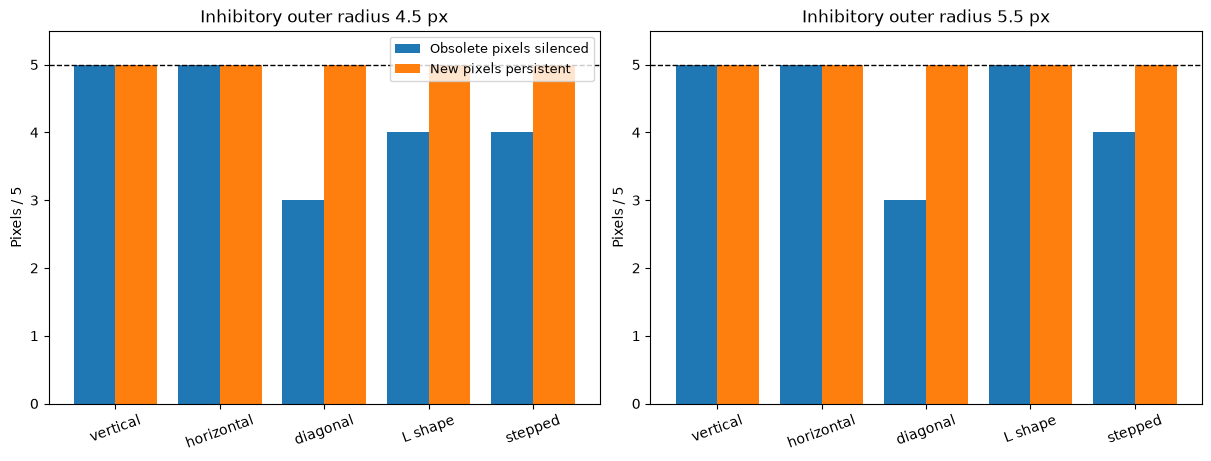

In [7]:
comparison = []
for radius in tqdm((4.5, 5.5), desc="Fixed-radius comparison"):
    for geometry, (old, new) in shapes.items():
        comparison.append(dict(outer_radius=radius, geometry=geometry,
                               **evaluate(old, new, outer_radius=radius)))
comparison = pd.DataFrame(comparison)
display(comparison)
display(comparison.groupby("outer_radius").success.agg(["sum", "count"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, (radius, group) in zip(axes, comparison.groupby("outer_radius", sort=True)):
    x = np.arange(len(group))
    ax.bar(x-0.2, group.old_silent, 0.4, label="Obsolete pixels silenced")
    ax.bar(x+0.2, group.new_persistent, 0.4, label="New pixels persistent")
    ax.axhline(5, ls="--", color="black", linewidth=1)
    ax.set(xticks=x, xticklabels=group.geometry, ylim=(0, 5.5),
           ylabel="Pixels / 5", title=f"Inhibitory outer radius {radius:g} px")
    ax.tick_params(axis="x", rotation=20)
axes[0].legend(fontsize=9)
plt.show()

## 6. Decision rule and stopping point

**Accept the single radius change only if:** it improves the number of successful geometries **without making any of the previously passing vertical or horizontal cases fail**, and without reducing solo persistence, creating off-target activity, or eliminating the new shapes. Otherwise, retain the original selected architecture and explicitly document geometry-dependent suppression as a limitation.

This is a *small synthetic validation set*. Even a 5/5 result would not justify claiming generalization to arbitrary events. The next fixed stage is **held-out synthetic conditions and original-versus-ESCM-2.0 comparison on identical recordings**, not another series of ad hoc mechanisms.

The notebook intentionally reports both successes and failures and does not choose a modified model automatically.